# Buổi B1: Hồi quy tuyến tính đơn biến, một đường thẳng đi qua đám mây điểm

**Hiện trường.** Chị Mai quản lý một vườn ươm hoa iris. Đo **chiều dài** cánh hoa chỉ mất vài giây bằng thước. Đo **chiều rộng** thì phải dùng thước kẹp, chậm gấp nhiều lần. Vườn có 150 bông đã được đo đủ cả hai số. Chị hỏi: *"Nếu từ nay chỉ đo chiều dài, em có đoán được chiều rộng không, và đoán sai bao nhiêu?"*

Đây là bài toán **hồi quy** (đoán một con số, như đã học ở A6) với **một** cột đề bài. Mô hình đơn giản nhất cho nó là **đường thẳng**.

**Câu hỏi của buổi này:** *đường thẳng là gì, máy tìm nó thế nào, và các con số nó trả về nói lên điều gì?*

**Mindset của người làm dữ liệu:** trước khi tin một mô hình, hãy *nhìn* xem dữ liệu có thật sự nằm dọc một đường không, rồi *kiểm* xem đường đó đoán sai ở đâu.

**Lưu ý:** đây là dữ liệu mẫu của scikit-learn để học. Buổi này dùng lại cú pháp từ A1 đến A6 mà không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Nhìn dữ liệu: có đường thẳng nào ẩn trong đám mây điểm không? |
| Chặng 2 | Chuẩn bị X và y: hình dạng, kiểu dữ liệu, và chuyện NaN |
| Chặng 3 | `fit` thật sự làm gì: máy chọn đường nào, và vì sao |
| Chặng 4 | `intercept_` và `coef_`: đọc hai con số của đường thẳng |
| Chặng 5 | Kiểm định: các con số nói lên điều gì về độ tin cậy |
| Chặng 6 | Khi đường thẳng gặp giới hạn |

## Chặng 1: Nhìn dữ liệu, có đường thẳng nào ẩn trong đám mây điểm không?

**Câu hỏi:** trước khi dựng mô hình, dữ liệu trông thế nào?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True).frame
flowers = iris.rename(columns={"petal length (cm)": "petal_length", "petal width (cm)": "petal_width"})
flowers[["petal_length", "petal_width"]].head()

,petal_length,petal_width
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2


**Giải thích từng dòng**

- `from sklearn.datasets import load_iris`: (đã học cách lấy dữ liệu ở A1) lấy hàm mở bộ dữ liệu hoa iris: 150 bông thuộc 3 loài.
- `iris = load_iris(as_frame=True).frame`: mở thành bảng pandas, cùng cách như bảng bệnh nhân.
- `flowers = iris.rename(columns={...})`: **mới:** `.rename(columns={tên cũ: tên mới})` đổi tên cột. Tên gốc có dấu cách và ngoặc (`petal length (cm)`) rất khó gõ, nên ta đổi sang `petal_length`, `petal_width`: chữ thường, nối bằng gạch dưới. Đây cũng là quy ước đặt tên biến trong code.
- `flowers[["petal_length", "petal_width"]].head()`: (đã học `head`) xem 5 bông đầu, chỉ hai cột ta quan tâm. Hai cặp ngoặc vuông là chủ ý, sẽ giải thích ở chặng 2.

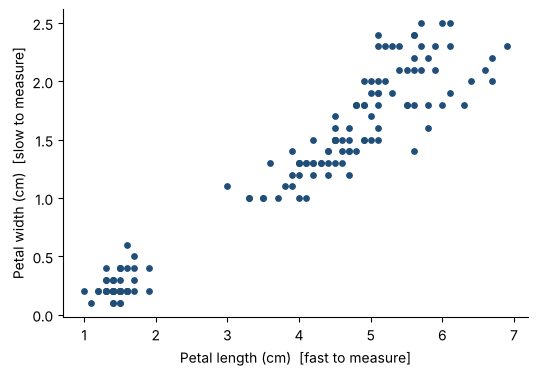

Correlation: 0.963


In [3]:
plt.scatter(flowers["petal_length"], flowers["petal_width"], color=BLUE, s=15)
plt.xlabel("Petal length (cm)  [fast to measure]")
plt.ylabel("Petal width (cm)  [slow to measure]")
plt.show()
print("Correlation:", round(flowers["petal_length"].corr(flowers["petal_width"]), 3))

**Giải thích từng dòng**

- `plt.scatter(..., color=BLUE, s=15)`: (đã học `scatter` ở A1) mỗi chấm là một bông hoa. `s=15` là cỡ chấm.
- `plt.xlabel(...); plt.ylabel(...); plt.show()`: (đã học) tên trục và hiện hình.
- `flowers["petal_length"].corr(flowers["petal_width"])`: (đã học `corr` ở A3, nhưng ở dạng cả bảng) đây là cách hỏi **riêng một cặp cột**: cột này gọi `.corr(cột kia)`.

**Cách đọc**

- **Con số:** tương quan 0,96, rất gần 1. Hai cột gần như tăng cùng nhau.
- **Bức tranh:** các chấm xếp thành một **dải chéo hẹp**, đi lên từ trái sang phải. Dải càng hẹp thì một đường thẳng đặt giữa dải càng đoán gần đúng. Nhưng để ý: có một **khoảng trống** quanh chiều dài 2,5 đến 3 cm, các chấm tách thành hai đám. Chi tiết này sẽ quay lại ở chặng 6.
- **Mô hình cần dựng:** chiều rộng ≈ a + b × chiều dài. Hai số **a** (điểm xuất phát) và **b** (độ dốc) là thứ máy phải tìm.

Thử bằng tay trước. Ta kẻ ba đường *do ta tự chọn* và xem đường nào ôm sát dải chấm nhất:

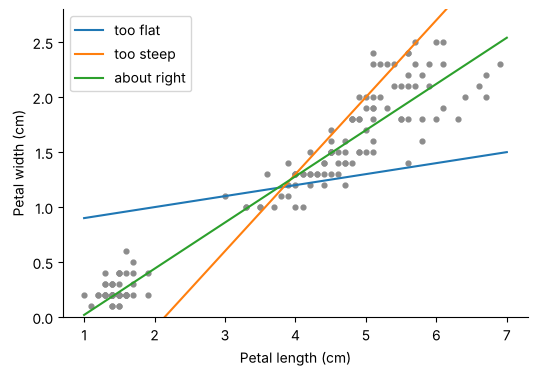

In [4]:
x = flowers["petal_length"]
y = flowers["petal_width"]
line_x = np.linspace(1, 7, 50)
guesses = {"too flat": (0.8, 0.1), "too steep": (-1.5, 0.7), "about right": (-0.4, 0.42)}
plt.scatter(x, y, color=GRAY, s=12)
for name, (a, b) in guesses.items():
    plt.plot(line_x, a + b * line_x, label=name)
plt.xlabel("Petal length (cm)"); plt.ylabel("Petal width (cm)")
plt.legend(); plt.ylim(0, 2.8); plt.show()

**Giải thích từng dòng**

- `x = flowers[...]; y = flowers[...]`: đặt tên ngắn cho hai cột để công thức gọn. Tạm dùng `x` và `y` viết thường vì đây là **một cột**; còn bảng nhiều cột thì ta dùng `X` hoa (xem chặng 2).
- `line_x = np.linspace(1, 7, 50)`: (đã học `linspace`) 50 điểm ngang từ 1 đến 7 để vẽ đường.
- `guesses = {"too flat": (0.8, 0.1), ...}`: từ điển: tên đường đi kèm cặp `(a, b)`. Ở đây `a` là điểm xuất phát, `b` là độ dốc.
- `for name, (a, b) in guesses.items():`: (đã học vòng lặp) lặp qua từng đường. `(a, b)` trong phần mở gói là **mở gói cặp con** ngay trong lúc lặp.
- `plt.plot(line_x, a + b * line_x, label=name)`: công thức đường thẳng y = a + b·x tính cho cả 50 điểm cùng lúc.
- `plt.ylim(0, 2.8)`: (đã học `set_ylim` ở A3, đây là dạng ngắn trên `plt`) giữ trục dọc từ 0 đến 2,8.

**Cách đọc:** đường "about right" ôm dải chấm tốt nhất; hai đường kia lệch hẳn. Mắt ta chọn được đường tốt, nhưng cần một **thước đo con số** để máy tự chọn. Máy sẽ làm ở chặng 3. Trước đó, cần chuẩn bị đúng đồ cho máy ăn.

**Mang về chặng 1:** hồi quy đơn biến là *tìm đường thẳng y = a + b·x ôm sát đám mây điểm*. Hai số cần tìm là **a** (điểm xuất phát) và **b** (độ dốc). Nên nhìn biểu đồ trước để biết dữ liệu có dạng dải thẳng hay không.

## Chặng 2: Chuẩn bị X và y, hình dạng, kiểu dữ liệu, và chuyện NaN

**Câu hỏi:** máy hồi quy tuyến tính đòi dữ liệu đầu vào ở dạng nào?

Ba quy tắc cần nhớ, và ta sẽ kiểm chứng từng quy tắc bằng code:

1. **X là bảng (2 chiều), y là một cột (1 chiều).**
2. **Mọi giá trị phải là số.**
3. **Không được có NaN (ô trống).**

In [5]:
X = flowers[["petal_length"]]
y = flowers["petal_width"]
print("X:", type(X).__name__, "shape", X.shape)
print("y:", type(y).__name__, "shape", y.shape)

X: DataFrame shape (150, 1)
y: Series shape (150,)


**Giải thích từng dòng**

- `X = flowers[["petal_length"]]`: **hai cặp ngoặc vuông** cho ra một **bảng** (DataFrame) có một cột. Cặp ngoặc ngoài là cú pháp chọn cột, cặp trong là **danh sách tên cột**. Đây là chữ **X hoa**: quy ước dành cho bảng đề bài, vì sau này có thể có nhiều cột.
- `y = flowers["petal_width"]`: **một cặp ngoặc** cho ra một **cột đơn** (Series). Chữ **y thường** dành cho đáp án.
- `print("X:", type(X).__name__, "shape", X.shape)`: `type(X).__name__` là cách hỏi "X thuộc loại gì". `X.shape` (đã học) cho `(150, 1)`: 150 dòng, 1 cột.

**Cách đọc**

- **Con số:** X có hình dạng `(150, 1)` (bảng 150 dòng 1 cột), y có hình dạng `(150,)` (một dãy 150 số).
- **Bức tranh:** hãy tưởng tượng X là **một tờ phiếu có nhiều ô để điền** (hôm nay chỉ có 1 ô, mai có thể 10 ô), còn y là **cột đáp án** bên cạnh. Máy luôn đòi X có dạng "bảng" dù chỉ có một cột, để cùng một đoạn code dùng được cho 1 cột hay 100 cột. Nếu đưa một cột đơn làm X, máy sẽ từ chối:

In [6]:
from sklearn.linear_model import LinearRegression
try:
    LinearRegression().fit(flowers["petal_length"], y)
except ValueError as err:
    print("ValueError:", str(err)[:160])

ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.


**Giải thích từng dòng**

- `from sklearn.linear_model import LinearRegression`: (đã học) máy hồi quy tuyến tính nằm trong module `linear_model` (các mô hình tuyến tính). Khi cần một mô hình, trước hết hỏi: *nó thuộc họ nào của sklearn?*
- `LinearRegression().fit(flowers["petal_length"], y)`: cố tình đưa **một cột đơn** làm X (chỉ một cặp ngoặc).
- `except ValueError as err:`: (đã học `try/except` ở A2) bắt lỗi thay vì để chương trình dừng. `as err` đặt tên `err` cho nội dung lỗi để in ra.
- `str(err)[:160]`: `str(...)` đổi lỗi thành chữ, `[:160]` lấy 160 ký tự đầu cho gọn (phép cắt lát).

**Cách đọc:** thông báo lỗi nói thẳng: máy cần dữ liệu **2 chiều**, còn bạn đưa 1 chiều. Cách sửa chính là hai cặp ngoặc vuông ở trên. Đây là lỗi gặp **nhiều nhất** của người mới học sklearn, nên hãy nhớ: *X hoa là bảng, y thường là cột*.

Quy tắc 3: thử để một ô trống (NaN) vào X:

In [7]:
X_dirty = X.copy()
X_dirty.loc[0, "petal_length"] = np.nan
try:
    LinearRegression().fit(X_dirty, y)
except ValueError as err:
    print("ValueError:", str(err)[:90])

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN nativ


**Giải thích từng dòng**

- `X_dirty = X.copy()`: (đã học `copy`) bản sao để không làm hỏng X gốc.
- `X_dirty.loc[0, "petal_length"] = np.nan`: (đã học ở A2) xóa giá trị dòng đầu, thay bằng ô trống.
- `LinearRegression().fit(X_dirty, y)`: cố huấn luyện trên dữ liệu có ô trống.

**Cách đọc:** **LinearRegression không chấp nhận NaN**: nó báo lỗi ngay. Máy chỉ biết làm phép tính trên số, mà "trống" thì không cộng trừ nhân chia được. Bạn **phải xử lý NaN trước** khi `fit` (xóa dòng hoặc điền giá trị, như đã học ở A2). Có mô hình tự chịu được NaN (ví dụ một số loại cây quyết định ở phần C), nhưng đừng giả định: mỗi mô hình mới, hãy kiểm tra.

Quy tắc 2 (kiểu dữ liệu): cột chữ, như tên loài "setosa", cũng không đưa thẳng vào được. Phải đổi chữ thành số trước (sẽ học ở B4).

**Mang về chặng 2:** X là bảng 2 chiều (hai cặp ngoặc), y là cột 1 chiều. Cả hai phải là số và **không có NaN**. Họ mô hình "tuyến tính" nằm ở `sklearn.linear_model`.

## Chặng 3: `fit` thật sự làm gì, máy chọn đường nào, và vì sao

**Câu hỏi:** ở chặng 1 ta chọn đường bằng mắt. Máy chọn bằng gì?

Máy cần một **thước đo độ tệ** của mỗi đường. Ý tưởng: với mỗi bông hoa, đo **khoảng cách dọc** từ chấm đến đường (đường đoán sai bao nhiêu cm). Rồi **bình phương** từng khoảng cách và cộng lại. Đường nào có tổng nhỏ nhất thì được chọn. Cách làm này tên là **bình phương tối thiểu** (least squares).

Vì sao bình phương? Vì sai lệch có thể là âm hoặc dương (chấm nằm trên hay dưới đường), bình phương làm chúng đều dương, đồng thời **phạt nặng hơn các sai lệch lớn**.

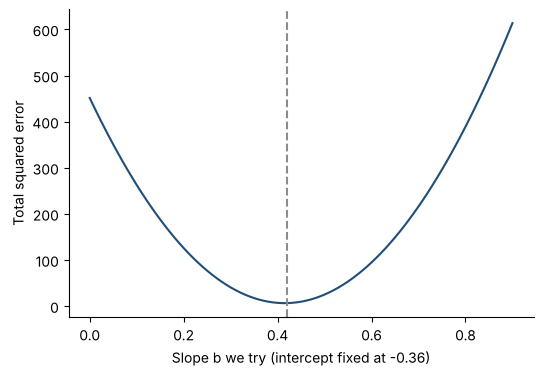

Best slope on this grid: 0.42


In [8]:
def total_error(a, b):
    errors = y - (a + b * x)
    return (errors ** 2).sum()

slopes = np.linspace(0, 0.9, 91)
totals = [total_error(-0.36, b) for b in slopes]
best = slopes[np.argmin(totals)]
plt.plot(slopes, totals, color=BLUE)
plt.axvline(best, color=GRAY, linestyle="--")
plt.xlabel("Slope b we try (intercept fixed at -0.36)")
plt.ylabel("Total squared error")
plt.show()
print("Best slope on this grid:", round(best, 2))

**Giải thích từng dòng**

- `def total_error(a, b):`: (đã học `def`) hàm nhận một đường `(a, b)` và trả về độ tệ của nó.
- `errors = y - (a + b * x)`: với **mọi** bông hoa cùng lúc: đáp án thật trừ giá trị đường đoán. Pandas tự trừ từng cặp.
- `return (errors ** 2).sum()`: (đã học `**`, `.sum()`) bình phương từng sai lệch rồi cộng tất cả lại thành **một con số**.
- `slopes = np.linspace(0, 0.9, 91)`: 91 độ dốc thử, từ 0 đến 0,9, cách nhau 0,01. Ta giữ `a = -0,36` cố định để vẽ được đồ thị 2 chiều.
- `totals = [total_error(-0.36, b) for b in slopes]`: (đã học list comprehension) tính độ tệ cho từng độ dốc thử.
- `best = slopes[np.argmin(totals)]`: (đã học `argsort` ở A2) `np.argmin` trả về **vị trí** của số nhỏ nhất; dùng vị trí đó lấy độ dốc tương ứng.

**Cách đọc**

- **Con số:** độ dốc tốt nhất trong lưới thử khoảng 0,42 (máy sẽ tìm ra 0,413, chính xác hơn lưới 0,01).
- **Bức tranh:** đồ thị có hình **cái bát**, giống bài A1. Độ dốc quá nhỏ hoặc quá lớn đều làm tổng sai số vọt lên; đáy bát là điểm tốt nhất. Đường thẳng nhận lấy độ dốc ở **đáy bát**. Đó chính là việc `fit` làm, chỉ khác là máy giải thẳng bằng công thức toán chứ không thử từng điểm, và tìm cùng lúc cả `a` lẫn `b`.

Giờ gọi máy thật. Ta tách một phần hoa ra để dành thi, như học ở A4:

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("Fitted on", len(X_train), "flowers, kept", len(X_test), "for the test")

Fitted on 120 flowers, kept 30 for the test


**Giải thích từng dòng**

- `from sklearn.model_selection import train_test_split`: (đã học ở A4).
- `X_train, ... = train_test_split(X, y, test_size=0.2, random_state=42)`: (đã học ở A4) 80% hoa để học, 20% để thi; hạt giống 42 cố định cách chia.
- `model = LinearRegression()`: tạo một cái máy **chưa học gì**: giống một cuốn vở trắng.
- `model.fit(X_train, y_train)`: **`fit` nghĩa là "học từ dữ liệu"**: máy nhìn các cặp (đề, đáp án) trong tập học, tìm đường bình phương tối thiểu, và **ghi kết quả vào chính nó** (vào `intercept_` và `coef_`). Gọi `fit` xong thì máy hết "trắng". Cú pháp này giống mọi mô hình trong sklearn.

**Ba động từ của sklearn, đọc một lần dùng mãi**

| Động từ | Nghĩa | Ví dụ |
|---|---|---|
| `fit(X, y)` | **Học** từ dữ liệu, kết quả lưu trong máy | tìm đường thẳng |
| `predict(X)` | **Đoán** cho dữ liệu mới, dùng cái đã học | đoán chiều rộng từ chiều dài |
| `transform(X)` | **Biến đổi** dữ liệu theo cái đã học | đổi thang đo (gặp ở B4) |

`LinearRegression` có `fit` và `predict`, **không có** `transform`, vì nó đoán chứ không biến đổi dữ liệu. Công cụ chuẩn hóa ở B4 mới có `transform`. Nhớ một quy tắc: `fit` **chỉ** dùng trên tập học, tuyệt đối không dùng tập thi (như A4 đã cảnh báo về rò rỉ dữ liệu).

**Mang về chặng 3:** `fit` = máy thử các đường và chọn đường có **tổng bình phương sai lệch nhỏ nhất** (đáy cái bát). Kết quả học được lưu ngay trong biến `model`.

## Chặng 4: `intercept_` và `coef_`, đọc hai con số của đường thẳng

**Câu hỏi:** máy đã học xong, vậy nó học được hai con số nào và chúng nghĩa là gì?

In [10]:
print("intercept_ (a):", round(model.intercept_, 3))
print("coef_      (b):", model.coef_.round(3))

intercept_ (a): -0.357
coef_      (b): [0.413]


**Giải thích từng dòng**

- `model.intercept_`: (đã học ở A1) **`a`**: điểm xuất phát của đường. Dấu gạch dưới cuối tên là quy ước sklearn cho "thứ chỉ có **sau khi** `fit`".
- `model.coef_`: **`b`**: độ dốc. Nó là một **mảng** vì khi có nhiều cột đề sẽ có nhiều độ dốc, mỗi cột một số. Hôm nay chỉ có một cột nên mảng có một phần tử.
- `.round(3)`: (đã học) làm tròn 3 chữ số.

**Cách đọc**

- **Con số:** `intercept_` khoảng **−0,36**, `coef_` khoảng **0,41**. Đường tìm được là: *chiều rộng ≈ −0,36 + 0,41 × chiều dài*.
- **Ý nghĩa của `coef_`** (quan trọng nhất): **cánh hoa dài thêm 1 cm thì dự đoán rộng thêm khoảng 0,41 cm.** Dài thêm 2 cm thì rộng thêm khoảng 0,83 cm. Đây là con số bạn đưa cho chị Mai: *mỗi cm chiều dài "kéo theo" 0,4 cm chiều rộng*. Chữ "kéo theo" chứ không phải "gây ra": ta chỉ thấy hai số đi cùng nhau, chưa chứng minh cái này sinh ra cái kia.
- **Ý nghĩa của `intercept_`:** chiều rộng dự đoán khi chiều dài bằng **0**. Ở đây ra số **âm** (−0,36 cm), tức là vô lý: cánh hoa không thể rộng âm. Ta sẽ xem vì sao bên dưới.

Kiểm chứng rằng `predict` không có phép màu nào, chỉ là công thức a + b·x:

In [11]:
new_flowers = pd.DataFrame({"petal_length": [1.0, 4.0, 6.0]})
by_machine = model.predict(new_flowers)
by_hand = model.intercept_ + model.coef_[0] * new_flowers["petal_length"]
pd.DataFrame({"length": new_flowers["petal_length"], "machine": by_machine.round(3), "by hand": by_hand.round(3)})

,length,machine,by hand
0,1.0,0.057,0.057
1,4.0,1.296,1.296
2,6.0,2.123,2.123


**Giải thích từng dòng**

- `new_flowers = pd.DataFrame({"petal_length": [1.0, 4.0, 6.0]})`: (đã học) tạo ba bông hoa mới. Chú ý vẫn là **bảng** với **đúng tên cột** `petal_length` như lúc học: quy tắc ở chặng 2.
- `by_machine = model.predict(new_flowers)`: (đã học) máy đoán.
- `by_hand = model.intercept_ + model.coef_[0] * new_flowers["petal_length"]`: tự tính tay a + b·x. `model.coef_[0]` lấy phần tử đầu của mảng `coef_` thành **một số** để nhân.
- `pd.DataFrame({"length": ..., "machine": ..., "by hand": ...})`: (đã học) xếp ba cột cạnh nhau để so.

**Cách đọc:** hai cột "machine" và "by hand" **giống hệt nhau**. `predict` chỉ là thay số vào a + b·x. Không có gì bí ẩn trong hộp.

Ba bông hoa cho ba dự đoán: dài 1 cm thì dự đoán rộng khoảng 0,06 cm; dài 4 cm thì 1,30 cm; dài 6 cm thì 2,12 cm. Để ý số đầu: **0,06 cm** gần bằng 0, **sát mép âm**. Hãy xem đường thẳng đi vào vùng nào của biểu đồ:

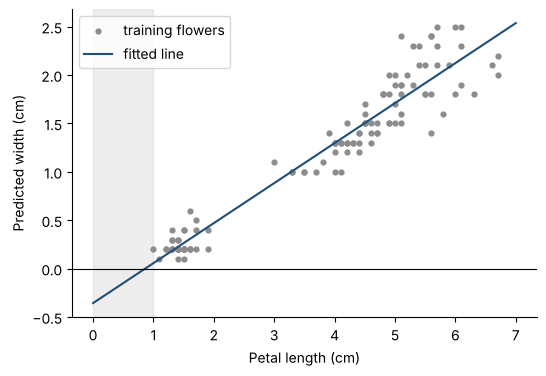

In [12]:
line_x = np.linspace(0, 7, 50)
plt.scatter(X_train["petal_length"], y_train, color=GRAY, s=12, label="training flowers")
plt.plot(line_x, model.predict(pd.DataFrame({"petal_length": line_x})), color=BLUE, label="fitted line")
plt.axvspan(0, X_train["petal_length"].min(), color=GRAY, alpha=0.15)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Petal length (cm)"); plt.ylabel("Predicted width (cm)")
plt.legend(loc="upper left"); plt.show()

**Giải thích từng dòng**

- `line_x = np.linspace(0, 7, 50)`: kéo dài đường về tận chiều dài 0 để thấy chỗ cắt trục dọc.
- `model.predict(pd.DataFrame({"petal_length": line_x}))`: dự đoán cho cả 50 điểm; cần bọc vào bảng một cột đúng tên.
- `plt.axvspan(0, X_train["petal_length"].min(), color=GRAY, alpha=0.15)`: (đã học `axvspan` ở A1) tô xám **vùng không có hoa nào** (từ 0 đến bông ngắn nhất). `.min()` là giá trị nhỏ nhất.
- `plt.axhline(0, color="black", linewidth=0.8)`: (đã học) vạch ngang ở số 0.

**Cách đọc**

- **Con số:** bông hoa ngắn nhất trong dữ liệu dài khoảng 1 cm. Vùng xám (chiều dài từ 0 đến 1 cm) **không có hoa nào**.
- **Bức tranh:** đường thẳng được kéo qua vùng xám xuống cắt trục dọc ở −0,36, nhưng **máy chưa từng thấy bông hoa nào ở đó**. Đây là **ngoại suy** (đã gặp ở A4): đường thẳng là một lời hứa "cứ thẳng như thế mãi", không có gì đảm bảo ngoài vùng dữ liệu.
- **Bài học:** `intercept_` thường **chỉ là điểm neo của công thức**, không phải một dự đoán có nghĩa. Chỉ đọc nó như "giá trị khi x = 0" nếu x = 0 nằm trong vùng dữ liệu thật (ví dụ: x là số năm kinh nghiệm, x = 0 là người mới vào nghề). Còn `coef_` thì đọc được trong **vùng dữ liệu**, đó là con số có giá trị thực tế.

**Mang về chặng 4:** `coef_` là *thêm 1 đơn vị đề thì đáp án đổi bao nhiêu*; `intercept_` là *điểm neo của đường*; `predict` chỉ là thay số vào a + b·x. Đừng hiểu `intercept_` quá sát nghĩa nếu x = 0 nằm ngoài dữ liệu.

## Chặng 5: Kiểm định, các con số nói lên điều gì về độ tin cậy

**Câu hỏi:** đường đã có. Dùng nó cho chị Mai thì tin được đến đâu?

Ta chấm trên **tập thi**, đã giấu máy từ đầu. Lần này có hai thước đo: sai lệch trung bình (MAE, quen từ A1) và một thước đo mới là **R²**.

In [13]:
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor
pred = model.predict(X_test)
lazy = DummyRegressor().fit(X_train, y_train)
print("MAE  line:", round(mean_absolute_error(y_test, pred), 3), "cm | lazy (always the mean):", round(mean_absolute_error(y_test, lazy.predict(X_test)), 3), "cm")
print("R2   line (test):", round(model.score(X_test, y_test), 3), "| line (train):", round(model.score(X_train, y_train), 3), "| lazy:", round(lazy.score(X_test, y_test), 3))

MAE  line: 0.168 cm | lazy (always the mean): 0.708 cm
R2   line (test): 0.928 | line (train): 0.927 | lazy: -0.01


**Giải thích từng dòng**

- `from sklearn.metrics import mean_absolute_error`: lấy hàm tính **MAE** có sẵn của sklearn (ở A1 ta tính tay bằng `.abs().mean()`). Module `metrics` gom các thước đo.
- `from sklearn.dummy import DummyRegressor`: (đã học ở A5) máy mốc luôn đoán trung bình.
- `pred = model.predict(X_test)`: đường đoán cho tập thi.
- `lazy = DummyRegressor().fit(X_train, y_train)`: máy mốc lười.
- `mean_absolute_error(y_test, pred)`: `(đáp án thật, đáp án đoán)`: thứ tự này, đáp án thật đứng **trước**.
- `model.score(X_test, y_test)`: **mới với máy hồi quy:** `.score(X, y)` của mô hình hồi quy trả về **R²** (đọc là "R bình").

**Cách đọc**

- **Con số:** đường thẳng sai trung bình khoảng **0,17 cm**, còn mốc lười sai khoảng **0,71 cm**. R² của đường trên tập thi là **0,93**, của mốc lười là **−0,01**.
- **R² nghĩa là gì:** nó cho biết đường giải thích được **bao nhiêu phần trăm sự dao động** của đáp án. Cứ tưởng tượng chiều rộng các bông hoa dao động từ 0,1 đến 2,5 cm; nếu chỉ biết trung bình thì ta không giải thích được dao động nào (R² = 0). Biết chiều dài thì ta giải thích được **khoảng 93%** dao động đó. R² = 1 là hoàn hảo, R² = 0 là *tệ ngang mốc lười*, R² **âm** là *tệ hơn cả mốc lười*.
- **Hai số R² của đường** (train 0,927, test 0,928) **gần nhau**: máy không học vẹt. Nhớ lại A4: nếu train cao vọt còn test thấp mới đáng lo.
- **Kết luận cho chị Mai:** từ nay chỉ cần đo chiều dài, đoán chiều rộng sai trung bình khoảng **1,7 mm**. Tốt hơn đoán trung bình **4 lần**.

Nhưng sai trung bình 0,17 cm là **tốt hay không** còn tùy bông hoa to hay nhỏ. Điều tra tiếp: sai số có đều nhau giữa ba loài không?

In [14]:
species = iris.loc[X_test.index, "target"].map({0: "setosa", 1: "versicolor", 2: "virginica"})
report = pd.DataFrame({
    "species": species,
    "true_width": y_test,
    "abs_error": (y_test - pred).abs(),
})
by_species = report.groupby("species").agg(flowers=("true_width", "size"), avg_width=("true_width", "mean"), avg_error=("abs_error", "mean"))
by_species["error_pct"] = (by_species["avg_error"] / by_species["avg_width"] * 100).round(0)
by_species.round(3)

,flowers,avg_width,avg_error,error_pct
species,,,,
setosa,10,0.250,0.091,36.0
versicolor,9,1.344,0.135,10.0
virginica,11,2.118,0.266,13.0


**Giải thích từng dòng**

- `species = iris.loc[X_test.index, "target"].map({...})`: `X_test.index` là **số thứ tự dòng gốc** của các bông trong tập thi; `iris.loc[...]` lấy lại cột `target` (loài) cho đúng những bông đó; `.map` (đã học) đổi 0/1/2 thành tên loài.
- `report = pd.DataFrame({"species": ..., "true_width": ..., "abs_error": ...})`: bảng điều tra: mỗi bông có loài, chiều rộng thật và sai số tuyệt đối. Pandas ghép đúng dòng nhờ **số thứ tự dòng** chung.
- `report.groupby("species").agg(flowers=(...), avg_width=(...), avg_error=(...))`: (đã học `groupby`) **mới:** `.agg(tên_mới=(cột, phép_tính))` tính **nhiều thống kê một lúc**, đặt tên cho từng cột kết quả. `"size"` là đếm số dòng, `"mean"` là trung bình.
- `by_species["error_pct"] = ... * 100`: sai số **tương đối**: sai số chia chiều rộng thật, nhân 100 ra phần trăm.

**Cách đọc**

- **Con số:** sai số **tuyệt đối** lớn nhất ở virginica (khoảng 0,27 cm) và nhỏ nhất ở setosa (khoảng 0,09 cm). Nhưng sai số **tương đối** thì ngược lại: setosa (cánh hẹp, chiều rộng trung bình khoảng 0,25 cm) bị sai khoảng **36%**, còn versicolor và virginica chỉ khoảng **10 đến 13%**.
- **Bức tranh:** sai 0,09 cm trên bông rộng 0,25 cm là *lệch hơn một phần ba*; sai 0,27 cm trên bông rộng 2 cm là *chưa đến một phần bảy*. Con số tổng "sai 0,17 cm" **che mất** điều này: nhìn sai số tuyệt đối thì setosa có vẻ tốt nhất, nhìn sai số tương đối thì lại yếu nhất.
- **Một điều thành thật:** mỗi nhóm chỉ có 9 đến 11 bông trong tập thi, nên các con số này dao động nhiều (nhớ A4). Dùng chúng để *biết nơi cần nghi ngờ*, chưa phải để kết luận chắc chắn.
- **Bài học nghề:** đừng dừng ở con số tổng. Luôn **xẻ sai số theo nhóm** (như loài, vùng, khách hàng...) và xem **cả hai cách đo** (tuyệt đối và tương đối) để tìm chỗ mô hình yếu. Nếu chị Mai chủ yếu trồng setosa, sai lệch tương đối 36% là điều chị cần biết trước khi dùng.

**Mang về chặng 5:** đọc kiểm định theo bốn câu hỏi: (1) **MAE** là sai trung bình bao nhiêu đơn vị thật? (2) có hơn **mốc lười** không? (3) **R²** giải thích được bao nhiêu phần dao động, và train với test có gần nhau không? (4) sai số có **đều** giữa các nhóm không?

## Chặng 6: Khi đường thẳng gặp giới hạn

**Câu hỏi:** ở chặng 1 ta thấy một khoảng trống trong đám mây điểm. Đường thẳng đẹp là nhờ đâu?

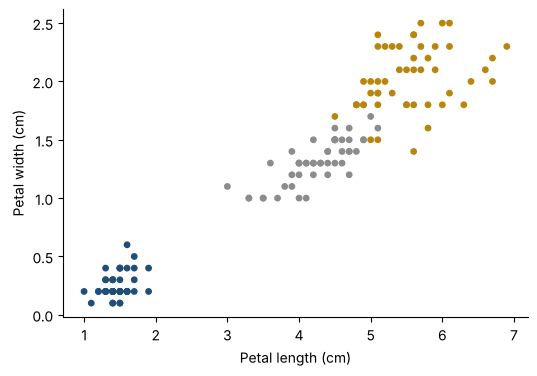

Correlation overall: 0.96 | inside setosa only: 0.33


In [15]:
colors = flowers["target"].map({0: BLUE, 1: GRAY, 2: "#B8860B"})
plt.scatter(x, y, c=colors, s=15)
plt.xlabel("Petal length (cm)"); plt.ylabel("Petal width (cm)")
plt.show()
setosa = flowers[flowers["target"] == 0]
print("Correlation overall:", round(x.corr(y), 2), "| inside setosa only:", round(setosa["petal_length"].corr(setosa["petal_width"]), 2))

**Giải thích từng dòng**

- `colors = flowers["target"].map({0: BLUE, 1: GRAY, 2: "#B8860B"})`: (đã học `.map`) đổi mã loài thành **màu**: setosa xanh đậm, versicolor xám, virginica vàng sẫm.
- `plt.scatter(x, y, c=colors, s=15)`: (đã học `c=`) tô từng chấm theo màu loài.
- `setosa = flowers[flowers["target"] == 0]`: (đã học lọc dòng) chỉ giữ bông loài setosa.
- `x.corr(y) ... setosa["petal_length"].corr(setosa["petal_width"])`: so tương quan toàn bộ và tương quan **riêng trong một loài**.

**Cách đọc**

- **Con số:** tương quan toàn bộ là 0,96, nhưng **chỉ riêng trong loài setosa** là khoảng **0,33**: yếu.
- **Bức tranh:** đám mây gồm **ba cụm màu** nằm gần nhau theo đường chéo. Phần lớn "độ thẳng" đến từ việc *ba loài khác nhau ở kích cỡ*, chứ không phải trong từng loài, chiều dài hứa hẹn nhiều về chiều rộng. Khoảng trống chiều dài 2,5 đến 3 cm chính là **khe giữa setosa và hai loài kia**.
- **Hệ quả:** đường thẳng chung đang làm việc của *"đoán loài rồi đoán kích cỡ"*. Nếu chị Mai biết loài, một đường riêng cho từng loài, hoặc thêm cột loài vào mô hình (sẽ học ở B3 và B4), sẽ tốt hơn.

Còn khi dữ liệu không dọc theo đường nào cả thì sao? Thử với bảng bệnh nhân quen thuộc ở các buổi trước:

Patients: slope [10.76] | R2 on test: 0.23 | MAE: 52.3


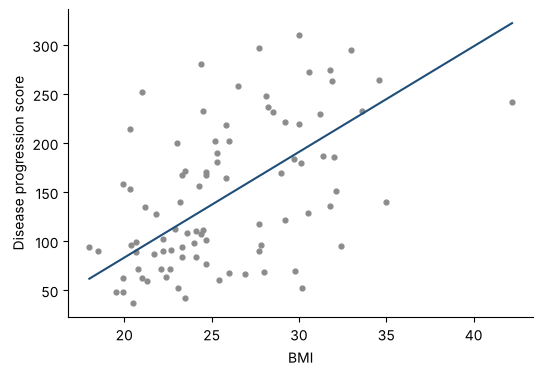

In [16]:
from sklearn.datasets import load_diabetes
patients = load_diabetes(as_frame=True, scaled=False).frame
Xp, yp = patients[["bmi"]], patients["target"]
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, test_size=0.2, random_state=42)
weak = LinearRegression().fit(Xp_train, yp_train)
print("Patients: slope", weak.coef_.round(2), "| R2 on test:", round(weak.score(Xp_test, yp_test), 2), "| MAE:", round(mean_absolute_error(yp_test, weak.predict(Xp_test)), 1))
plt.scatter(Xp_test["bmi"], yp_test, color=GRAY, s=12)
xs = np.linspace(Xp["bmi"].min(), Xp["bmi"].max(), 50)
plt.plot(xs, weak.predict(pd.DataFrame({"bmi": xs})), color=BLUE)
plt.xlabel("BMI"); plt.ylabel("Disease progression score"); plt.show()

**Giải thích từng dòng**

- `patients = load_diabetes(as_frame=True, scaled=False).frame`: (đã học) bảng bệnh nhân ở A1 đến A6.
- `Xp, yp = patients[["bmi"]], patients["target"]`: cùng quy tắc chặng 2: X hai cặp ngoặc, y một cặp. Đặt hậu tố `p` (patients) để không đè lên `X`, `y` của hoa.
- `weak = LinearRegression().fit(Xp_train, yp_train)`: huấn luyện cùng cách; chỉ thay dữ liệu.
- `weak.coef_.round(2) ... weak.score(...) ... mean_absolute_error(...)`: in độ dốc, R² và MAE trên tập thi.

**Cách đọc**

- **Con số:** độ dốc 10,8 (BMI tăng 1 thì điểm tiến triển dự đoán tăng khoảng 10,8), nhưng R² chỉ khoảng **0,23**, MAE khoảng 52 điểm.
- **Bức tranh:** các chấm tỏa như **đám sương**, đường thẳng đi giữa nhưng nhiều chấm cách xa rất xa. Với chị Hạnh, BMI một mình giải thích được **chưa đến một phần tư** dao động của bệnh nhân. Đó là lý do ta cần *nhiều cột đề* (B3).
- **So sánh hai trường hợp:** hoa iris R² = 0,93, bệnh nhân R² = 0,23. Cùng một thuật toán, cùng một cách đọc; khác nhau ở chỗ **dữ liệu có thật sự nằm dọc một đường hay không**. Mô hình không tự "phép màu" tạo ra độ chính xác.

## Phán quyết và bài học nghề

**Phán quyết cho chị Mai.** Có thể ước chiều rộng cánh hoa từ chiều dài: *đường thẳng chiều rộng ≈ −0,36 + 0,41 × chiều dài*, sai trung bình khoảng **1,7 mm** (tốt hơn đoán trung bình 4 lần), R² khoảng 0,93. **Nhưng** với loài cánh hẹp (setosa) sai số tương đối khá lớn (khoảng 36%), và đường này phần lớn đang "nhờ" sự khác biệt giữa các loài. Nếu biết loài thì nên thêm vào mô hình.

**Bài học nghề.**

1. **Nhìn trước, dựng sau:** biểu đồ điểm cho biết dữ liệu có dạng dải thẳng không.
2. **Giữ ba quy tắc đầu vào:** X là bảng, y là cột, mọi giá trị là số và không có NaN.
3. **`fit` = học, `predict` = đoán.** Kết quả học nằm trong `intercept_` và `coef_`; đọc `coef_` trong vùng dữ liệu.
4. **Đọc kiểm định bốn tầng:** MAE theo đơn vị thật, so với mốc lười, R² và độ lệch train/test, sai số theo nhóm.
5. **Đường thẳng chỉ trả lời tốt khi dữ liệu nằm dọc một đường.** Khi không, hãy thêm cột đề hoặc đổi mô hình.

**Một điều thành thật:** bộ hoa iris là một trong những bộ dữ liệu "đẹp" nhất để dạy hồi quy. Dữ liệu ngoài đời hiếm khi gọn như vậy, và R² 0,93 là điều hiếm gặp, đặc biệt với dữ liệu về con người.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Hồi quy đơn biến là tìm đường y = a + b·x ôm sát đám mây điểm. |
| 2 | X là bảng 2 chiều (hai cặp ngoặc), y là cột 1 chiều; phải là số, không NaN. Mô hình tuyến tính ở `sklearn.linear_model`. |
| 3 | `fit` chọn đường có tổng bình phương sai lệch nhỏ nhất. `fit` học, `predict` đoán, `transform` biến đổi dữ liệu. |
| 4 | `coef_` là độ đổi của đáp án khi đề tăng 1 đơn vị; `intercept_` là điểm neo, thường không có nghĩa nếu x = 0 ngoài dữ liệu. |
| 5 | Kiểm định bốn tầng: MAE, mốc lười, R² (train so với test), sai số theo nhóm. |
| 6 | Đường thẳng chỉ tốt khi dữ liệu nằm dọc một đường; đám mây tỏa rộng thì R² thấp. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Đường thẳng đi qua đám mây điểm | hồi quy tuyến tính đơn biến | `LinearRegression()` |
| Máy học từ ví dụ | huấn luyện | `model.fit(X_train, y_train)` |
| Máy đoán cho hoa mới | dự đoán | `model.predict(X_new)` |
| Điểm xuất phát của đường | hệ số chặn (intercept) | `model.intercept_` |
| Độ dốc: đề tăng 1 thì đáp án đổi bao nhiêu | hệ số (coefficient) | `model.coef_` |
| Sai trung bình theo đơn vị thật | MAE | `mean_absolute_error(y, pred)` |
| Phần dao động mà đường giải thích được | R² | `model.score(X, y)` |
| Cách chọn đường: tổng bình phương sai lệch nhỏ nhất | bình phương tối thiểu | (làm trong `fit`) |
| Đổi tên cột cho dễ gõ | đổi tên cột | `df.rename(columns={...})` |

**Thử thách tự làm**

1. Dùng hoa iris, đổi đề thành `sepal_length` (chiều dài đài hoa) và đáp án vẫn là `petal_width`. R² thay đổi thế nào so với 0,93? Cột nào đề tốt hơn?
2. Đổi `random_state` từ 42 sang 0, 1, 2 rồi in `coef_` và R² trên tập thi. Con số nào ổn định, con số nào dao động? (Gợi ý: nhớ bài A4, mỗi lần chia là một kết quả khác.)
3. Kể một câu chuyện với bộ dữ liệu khác: dùng `load_wine(as_frame=True)`, chọn hai cột số (ví dụ `alcohol` và `color_intensity`), vẽ biểu đồ điểm, dựng đường thẳng, đọc `coef_` bằng lời đời thường và chạy kiểm định bốn tầng.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích được y = a + b·x và vai trò của a, b.
- [ ] Tạo đúng X (bảng) và y (cột), và biết vì sao NaN gây lỗi.
- [ ] Phân biệt `fit`, `predict`, `transform`.
- [ ] Đọc `coef_` bằng một câu đời thường, và biết khi nào không đọc `intercept_` sát nghĩa.
- [ ] Giải thích MAE, R², và so với mốc lười.
- [ ] Biết xẻ sai số theo nhóm để tìm chỗ mô hình yếu.

## Phần thưởng (Tip pro): Độ dốc tính bằng công thức, không cần máy


`coef_` của hồi quy đơn biến có công thức đóng, bạn có thể tự tính để thấy `fit` không có phép màu: **độ dốc = hiệp phương sai của x và y, chia cho phương sai của x**. Chạy ô dưới để đối chiếu với `model.coef_`.

In [17]:
b_manual = np.cov(X_train["petal_length"], y_train)[0, 1] / np.var(X_train["petal_length"], ddof=1)
a_manual = y_train.mean() - b_manual * X_train["petal_length"].mean()
print("by formula:", round(a_manual, 4), round(b_manual, 4), "| by sklearn:", round(model.intercept_, 4), model.coef_.round(4)[0])

by formula: -0.3567 0.4132 | by sklearn: -0.3567 0.4132


**Giải thích từng dòng**

- `np.cov(X_train["petal_length"], y_train)[0, 1]`: `np.cov` cho **bảng hiệp phương sai** 2×2; ô `[0, 1]` là hiệp phương sai giữa hai cột: hai số cùng tăng cùng giảm mạnh đến đâu.
- `np.var(X_train["petal_length"], ddof=1)`: phương sai của x (độ phân tán của chiều dài). `ddof=1` để cùng cách chia với `np.cov`.
- `a_manual = y_train.mean() - b_manual * X_train[...].mean()`: đường thẳng **luôn đi qua điểm trung bình** (trung bình x, trung bình y), nên `a` suy ra từ `b` và hai giá trị trung bình.